In [1]:
# Mount Drive and pin the shared project root.
# Notebooks 02-09 read this exact path, so 01 must write into it rather than the
# runtime-local ./outputs directory it used originally.

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/algoverse/dnabert")
OUTPUT_DIR = PROJECT_DIR / "outputs/promoter_baseline_pilot"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Baseline output directory:", OUTPUT_DIR)
print("Drive is writable:", OUTPUT_DIR.exists())

import torch

print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("WARNING: no GPU. Set Runtime > Change runtime type > T4 GPU, then rerun.")


Mounted at /content/drive
Project directory: /content/drive/MyDrive/algoverse/dnabert
Baseline output directory: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot
Drive is writable: True
CUDA available: True


In [2]:
# Pin DNABERT-2-compatible Hugging Face versions

!pip install -q \
    transformers==4.44.2 \
    tokenizers==0.19.1 \
    huggingface-hub==0.24.7

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 46.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.5/417.5 kB 17.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.39.0 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.24.7 which is incompatible.
peft 0.19.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.24.7 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.24.7 which is incompatible.


In [3]:
import torch
import transformers
import tokenizers
import huggingface_hub

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu128
Transformers: 4.44.2
Tokenizers: 0.19.1
Hugging Face Hub: 0.24.7
CUDA available: True


In [4]:
# Load the GUE core-promoter dataset

from datasets import load_dataset

promoter_dataset = load_dataset(
    "leannmlindsey/GUE",
    name="prom_core_all",
)

print(promoter_dataset)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

dev.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/47356 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5920 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/5920 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sequence', 'label'],
        num_rows: 47356
    })
    test: Dataset({
        features: ['sequence', 'label'],
        num_rows: 5920
    })
    dev: Dataset({
        features: ['sequence', 'label'],
        num_rows: 5920
    })
})


In [5]:
# Inspect the GUE promoter dataset

from collections import Counter
import pandas as pd
import numpy as np

summary_rows = []

for split_name, split in promoter_dataset.items():
    labels = split["label"]
    sequences = split["sequence"]
    lengths = [len(seq) for seq in sequences]

    label_counts = Counter(labels)

    summary_rows.append({
        "split": split_name,
        "num_examples": len(split),
        "label_0": label_counts.get(0, 0),
        "label_1": label_counts.get(1, 0),
        "mean_length": np.mean(lengths),
        "min_length": np.min(lengths),
        "max_length": np.max(lengths),
    })

dataset_summary = pd.DataFrame(summary_rows)

display(dataset_summary)

print("\nExample rows from the training split:")
display(promoter_dataset["train"].select(range(5)).to_pandas())

,split,num_examples,label_0,label_1,mean_length,min_length,max_length
0,train,47356,23705,23651,70.0,70,70
1,test,5920,2952,2968,70.0,70,70
2,dev,5920,2941,2979,70.0,70,70



Example rows from the training split:


,sequence,label
0,GCTAGCTCATCTTGCGGCTGGGCGGGGCCCAGGACTGCTGCTGCTG...,1
1,ATAAAGGGGGCATCTCGCAGCACCGGGGGCCCTAAGCAGCGAGACC...,1
2,GGGGAGCTCTGGGAACGGGGCCTGTGCGCACGCGCATCTGACGGTT...,1
3,GCCACCTGAGCGTAGGGCATACAGCCATTTTCTGGGCGGGGCGTGC...,0
4,GGAAAGAGCAGACAAACAGGAACAGAAGTTCTCACTCTAGGTCACG...,1


composition baseline

In [6]:
# Examine nucleotide composition by class

def sequence_features(sequence):
    sequence = sequence.upper()
    length = len(sequence)

    return {
        "gc_fraction": (sequence.count("G") + sequence.count("C")) / length,
        "a_fraction": sequence.count("A") / length,
        "c_fraction": sequence.count("C") / length,
        "g_fraction": sequence.count("G") / length,
        "t_fraction": sequence.count("T") / length,
    }


train_df = promoter_dataset["train"].to_pandas()

feature_df = train_df["sequence"].apply(
    lambda sequence: pd.Series(sequence_features(sequence))
)

train_features_df = pd.concat(
    [train_df, feature_df],
    axis=1,
)

composition_summary = (
    train_features_df
    .groupby("label")[
        [
            "gc_fraction",
            "a_fraction",
            "c_fraction",
            "g_fraction",
            "t_fraction",
        ]
    ]
    .agg(["mean", "std"])
)

display(composition_summary)

print("\nExample counts by label:")
display(train_features_df.groupby("label").size())

gc_fraction           a_fraction           c_fraction            \
             mean       std       mean       std       mean       std   
label                                                                   
0        0.541796  0.090830   0.228274  0.064520   0.264003  0.069347   
1        0.629067  0.126595   0.181656  0.081979   0.302218  0.095482   

      g_fraction           t_fraction            
            mean       std       mean       std  
label                                            
0       0.277793  0.070672   0.229930  0.065512  
1       0.326849  0.099966   0.189277  0.085694


Example counts by label:


,0
label,
0,23705
1,23651


simple composition classifier

In [7]:
# Train a logistic-regression baseline using only nucleotide composition

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    classification_report,
)

FEATURE_COLUMNS = [
    "gc_fraction",
    "a_fraction",
    "c_fraction",
    "g_fraction",
    "t_fraction",
]


def build_composition_dataframe(dataset_split):
    df = dataset_split.to_pandas()

    features = df["sequence"].apply(
        lambda sequence: pd.Series(sequence_features(sequence))
    )

    return pd.concat([df, features], axis=1)


train_composition_df = build_composition_dataframe(
    promoter_dataset["train"]
)

dev_composition_df = build_composition_dataframe(
    promoter_dataset["dev"]
)

test_composition_df = build_composition_dataframe(
    promoter_dataset["test"]
)

X_train = train_composition_df[FEATURE_COLUMNS]
y_train = train_composition_df["label"]

X_dev = dev_composition_df[FEATURE_COLUMNS]
y_dev = dev_composition_df["label"]

X_test = test_composition_df[FEATURE_COLUMNS]
y_test = test_composition_df["label"]

composition_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42,
)

composition_classifier.fit(X_train, y_train)

dev_predictions = composition_classifier.predict(X_dev)
dev_probabilities = composition_classifier.predict_proba(X_dev)[:, 1]

test_predictions = composition_classifier.predict(X_test)
test_probabilities = composition_classifier.predict_proba(X_test)[:, 1]

composition_results = pd.DataFrame([
    {
        "split": "dev",
        "accuracy": accuracy_score(y_dev, dev_predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_dev,
            dev_predictions,
        ),
        "roc_auc": roc_auc_score(
            y_dev,
            dev_probabilities,
        ),
    },
    {
        "split": "test",
        "accuracy": accuracy_score(y_test, test_predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test,
            test_predictions,
        ),
        "roc_auc": roc_auc_score(
            y_test,
            test_probabilities,
        ),
    },
])

display(composition_results)

print("\nTest classification report:")
print(classification_report(y_test, test_predictions))

,split,accuracy,balanced_accuracy,roc_auc
0,dev,0.66402,0.664151,0.715316
1,test,0.67500,0.675049,0.723532



Test classification report:
              precision    recall  f1-score   support

           0       0.67      0.69      0.68      2952
           1       0.68      0.66      0.67      2968

    accuracy                           0.68      5920
   macro avg       0.68      0.68      0.67      5920
weighted avg       0.68      0.68      0.67      5920



create balanced pilot subsets

In [8]:
# Create balanced pilot subsets for the first DNABERT representation scan

from datasets import Dataset

SEED = 42

TRAIN_PER_CLASS = 1000
DEV_PER_CLASS = 400
TEST_PER_CLASS = 400


def balanced_subset(dataset_split, per_class, seed):
    df = dataset_split.to_pandas()

    sampled_parts = []

    for label in sorted(df["label"].unique()):
        label_df = df[df["label"] == label]

        sampled = label_df.sample(
            n=per_class,
            random_state=seed,
            replace=False,
        )

        sampled_parts.append(sampled)

    subset_df = (
        pd.concat(sampled_parts)
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

    return Dataset.from_pandas(
        subset_df,
        preserve_index=False,
    )


pilot_train = balanced_subset(
    promoter_dataset["train"],
    per_class=TRAIN_PER_CLASS,
    seed=SEED,
)

pilot_dev = balanced_subset(
    promoter_dataset["dev"],
    per_class=DEV_PER_CLASS,
    seed=SEED,
)

pilot_test = balanced_subset(
    promoter_dataset["test"],
    per_class=TEST_PER_CLASS,
    seed=SEED,
)

print("Pilot train:", pilot_train)
print("Pilot dev:", pilot_dev)
print("Pilot test:", pilot_test)

print("\nPilot train label counts:")
print(Counter(pilot_train["label"]))

print("\nPilot dev label counts:")
print(Counter(pilot_dev["label"]))

print("\nPilot test label counts:")
print(Counter(pilot_test["label"]))

Pilot train: Dataset({
    features: ['sequence', 'label'],
    num_rows: 2000
})
Pilot dev: Dataset({
    features: ['sequence', 'label'],
    num_rows: 800
})
Pilot test: Dataset({
    features: ['sequence', 'label'],
    num_rows: 800
})

Pilot train label counts:
Counter({1: 1000, 0: 1000})

Pilot dev label counts:
Counter({1: 400, 0: 400})

Pilot test label counts:
Counter({1: 400, 0: 400})


load baseline DNABERT-2

In [9]:
# Load DNABERT-2 on CPU first, then move it to CUDA

import gc
import torch

from transformers import AutoTokenizer, AutoModel
from transformers.models.bert.configuration_bert import BertConfig

MODEL_NAME = "quietflamingo/dnabert2-no-flashattention"

# Clear objects left by the failed attempt.
for variable_name in ["backbone", "model", "config"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Prevent custom ALiBi tensors from being created on CUDA or meta
# while the model is still being constructed.
torch.set_default_device("cpu")

print("CUDA available:", torch.cuda.is_available())
print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)

print("Loading standard BertConfig...")

config = BertConfig.from_pretrained(MODEL_NAME)

config.pad_token_id = tokenizer.pad_token_id
config.output_hidden_states = False
config.return_dict = False

print("Tokenizer pad token ID:", tokenizer.pad_token_id)
print("Config pad token ID:", config.pad_token_id)

print("Constructing model on CPU...")

backbone = AutoModel.from_pretrained(
    MODEL_NAME,
    config=config,
    trust_remote_code=True,
    low_cpu_mem_usage=False,
    device_map=None,
)

print("Moving completed model to CUDA...")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

backbone = backbone.to(device)
backbone.eval()

print("\nModel loaded successfully.")
print("Model class:", backbone.__class__.__name__)
print("Hidden size:", backbone.config.hidden_size)
print("Number of layers:", backbone.config.num_hidden_layers)
print("Number of attention heads:", backbone.config.num_attention_heads)
print("Model device:", next(backbone.parameters()).device)

CUDA available: True
Loading tokenizer...


tokenizer_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Loading standard BertConfig...


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


...

bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_layers.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

/root/.cache/huggingface/modules/transformers_modules/quietflamingo/dnabert2-no-flashattention/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at quietflamingo/dnabert2-no-flashattention and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Moving completed model to CUDA...

Model loaded successfully.
Model class: BertModel
Hidden size: 768
Number of layers: 12
Number of attention heads: 12
Model device: cuda:0


register layer hooks and test one batch

In [10]:
# Register forward hooks to capture all 12 transformer-layer outputs

captured_layers = {}
hook_handles = []

def make_hook(layer_index):
    def hook(module, inputs, output):
        # DNABERT-2 layer output may be a tensor or tuple.
        hidden = output[0] if isinstance(output, tuple) else output
        captured_layers[layer_index] = hidden.detach()
    return hook


for layer_index, layer_module in enumerate(backbone.encoder.layer):
    handle = layer_module.register_forward_hook(
        make_hook(layer_index)
    )
    hook_handles.append(handle)

print(f"Registered {len(hook_handles)} layer hooks.")

# Test on a small batch from the pilot dataset.
test_sequences = pilot_train["sequence"][:4]

batch = tokenizer(
    test_sequences,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=128,
)

batch = {
    key: value.to(device)
    for key, value in batch.items()
}

captured_layers.clear()

with torch.no_grad():
    outputs = backbone(
        **batch,
        return_dict=False,
    )

print("Captured layers:", len(captured_layers))

for layer_index in sorted(captured_layers):
    print(
        f"Layer {layer_index + 1}:",
        tuple(captured_layers[layer_index].shape),
    )

Registered 12 layer hooks.
Captured layers: 12
Layer 1: (69, 768)
Layer 2: (69, 768)
Layer 3: (69, 768)
Layer 4: (69, 768)
Layer 5: (69, 768)
Layer 6: (69, 768)
Layer 7: (69, 768)
Layer 8: (69, 768)
Layer 9: (69, 768)
Layer 10: (69, 768)
Layer 11: (69, 768)
Layer 12: (69, 768)


reconstruct the batch and pool each layer

In [11]:
# Reconstruct flattened DNABERT-2 outputs into per-sequence representations

token_counts = batch["attention_mask"].sum(dim=1).tolist()

print("Non-padding token counts per sequence:", token_counts)
print("Total expected tokens:", sum(token_counts))
print("Captured flattened tokens:", captured_layers[0].shape[0])

assert sum(token_counts) == captured_layers[0].shape[0]


def split_and_mean_pool(flat_hidden, token_counts):
    """
    Split a flattened [total_tokens, hidden_size] tensor back into
    individual sequences and mean-pool each sequence.

    Special tokens are temporarily included; we will refine pooling later.
    """
    pooled_sequences = []
    start = 0

    for count in token_counts:
        end = start + count
        sequence_hidden = flat_hidden[start:end]

        pooled_sequences.append(
            sequence_hidden.mean(dim=0)
        )

        start = end

    return torch.stack(pooled_sequences)


test_pooled_by_layer = {}

for layer_index in sorted(captured_layers):
    pooled = split_and_mean_pool(
        captured_layers[layer_index],
        token_counts,
    )

    test_pooled_by_layer[layer_index] = pooled.cpu()

    print(
        f"Layer {layer_index + 1}:",
        tuple(pooled.shape),
    )

Non-padding token counts per sequence: [17, 19, 17, 16]
Total expected tokens: 69
Captured flattened tokens: 69
Layer 1: (4, 768)
Layer 2: (4, 768)
Layer 3: (4, 768)
Layer 4: (4, 768)
Layer 5: (4, 768)
Layer 6: (4, 768)
Layer 7: (4, 768)
Layer 8: (4, 768)
Layer 9: (4, 768)
Layer 10: (4, 768)
Layer 11: (4, 768)
Layer 12: (4, 768)


content-token mean pooling

In [12]:
# Mean-pool only biological sequence tokens, excluding [CLS] and [SEP]

def split_and_content_mean_pool(flat_hidden, token_counts):
    """
    Split flattened hidden states into sequences and mean-pool only
    content tokens, excluding the first and last special tokens.
    """
    pooled_sequences = []
    start = 0

    for count in token_counts:
        end = start + count
        sequence_hidden = flat_hidden[start:end]

        # DNABERT-2 tokenization includes:
        # first token = [CLS]
        # last token  = [SEP]
        content_hidden = sequence_hidden[1:-1]

        if content_hidden.shape[0] == 0:
            raise ValueError(
                "A sequence has no content tokens after removing "
                "[CLS] and [SEP]."
            )

        pooled_sequences.append(
            content_hidden.mean(dim=0)
        )

        start = end

    return torch.stack(pooled_sequences)


test_content_pooled_by_layer = {}

for layer_index in sorted(captured_layers):
    pooled = split_and_content_mean_pool(
        captured_layers[layer_index],
        token_counts,
    )

    test_content_pooled_by_layer[layer_index] = pooled.cpu()

    print(
        f"Layer {layer_index + 1}:",
        tuple(pooled.shape),
    )

Layer 1: (4, 768)
Layer 2: (4, 768)
Layer 3: (4, 768)
Layer 4: (4, 768)
Layer 5: (4, 768)
Layer 6: (4, 768)
Layer 7: (4, 768)
Layer 8: (4, 768)
Layer 9: (4, 768)
Layer 10: (4, 768)
Layer 11: (4, 768)
Layer 12: (4, 768)


representation extraction function

In [13]:
# Extract one pooled representation per sequence from every layer

from torch.utils.data import DataLoader
from tqdm.auto import tqdm


def extract_layer_representations(
    dataset_split,
    batch_size=32,
):
    """
    Extract content-token mean-pooled representations from all 12 layers.

    Returns:
        representations_by_layer:
            dict[layer_index] -> NumPy array [num_sequences, hidden_size]
        labels:
            NumPy array [num_sequences]
    """

    sequences = dataset_split["sequence"]
    labels = np.array(dataset_split["label"])

    dataloader = DataLoader(
        sequences,
        batch_size=batch_size,
        shuffle=False,
    )

    layer_batches = {
        layer_index: []
        for layer_index in range(backbone.config.num_hidden_layers)
    }

    for sequence_batch in tqdm(
        dataloader,
        desc="Extracting representations",
    ):
        encoded = tokenizer(
            list(sequence_batch),
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_counts = (
            encoded["attention_mask"]
            .sum(dim=1)
            .tolist()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        for layer_index in sorted(captured_layers):
            pooled = split_and_content_mean_pool(
                captured_layers[layer_index],
                token_counts,
            )

            layer_batches[layer_index].append(
                pooled.cpu()
            )

    representations_by_layer = {}

    for layer_index, batches in layer_batches.items():
        representations_by_layer[layer_index] = (
            torch.cat(batches, dim=0)
            .numpy()
        )

    return representations_by_layer, labels


# Smoke test on 32 examples before running the full pilot set.
smoke_subset = pilot_train.select(range(32))

smoke_representations, smoke_labels = (
    extract_layer_representations(
        smoke_subset,
        batch_size=16,
    )
)

print("Smoke-test labels shape:", smoke_labels.shape)

for layer_index in sorted(smoke_representations):
    print(
        f"Layer {layer_index + 1}:",
        smoke_representations[layer_index].shape,
    )

Extracting representations:   0%|          | 0/2 [00:00<?, ?it/s]

Smoke-test labels shape: (32,)
Layer 1: (32, 768)
Layer 2: (32, 768)
Layer 3: (32, 768)
Layer 4: (32, 768)
Layer 5: (32, 768)
Layer 6: (32, 768)
Layer 7: (32, 768)
Layer 8: (32, 768)
Layer 9: (32, 768)
Layer 10: (32, 768)
Layer 11: (32, 768)
Layer 12: (32, 768)


extract all pilot representations

In [14]:
# Extract representations for train, dev, and test pilot subsets

pilot_train_representations, pilot_train_labels = (
    extract_layer_representations(
        pilot_train,
        batch_size=32,
    )
)

pilot_dev_representations, pilot_dev_labels = (
    extract_layer_representations(
        pilot_dev,
        batch_size=32,
    )
)

pilot_test_representations, pilot_test_labels = (
    extract_layer_representations(
        pilot_test,
        batch_size=32,
    )
)

print("\nFinished extracting all pilot representations.")

for split_name, representations, labels in [
    ("train", pilot_train_representations, pilot_train_labels),
    ("dev", pilot_dev_representations, pilot_dev_labels),
    ("test", pilot_test_representations, pilot_test_labels),
]:
    print(f"\n{split_name.upper()}")
    print("Labels:", labels.shape)

    for layer_index in sorted(representations):
        print(
            f"Layer {layer_index + 1}:",
            representations[layer_index].shape,
        )

Extracting representations:   0%|          | 0/63 [00:00<?, ?it/s]

Extracting representations:   0%|          | 0/25 [00:00<?, ?it/s]

Extracting representations:   0%|          | 0/25 [00:00<?, ?it/s]


Finished extracting all pilot representations.

TRAIN
Labels: (2000,)
Layer 1: (2000, 768)
Layer 2: (2000, 768)
Layer 3: (2000, 768)
Layer 4: (2000, 768)
Layer 5: (2000, 768)
Layer 6: (2000, 768)
Layer 7: (2000, 768)
Layer 8: (2000, 768)
Layer 9: (2000, 768)
Layer 10: (2000, 768)
Layer 11: (2000, 768)
Layer 12: (2000, 768)

DEV
Labels: (800,)
Layer 1: (800, 768)
Layer 2: (800, 768)
Layer 3: (800, 768)
Layer 4: (800, 768)
Layer 5: (800, 768)
Layer 6: (800, 768)
Layer 7: (800, 768)
Layer 8: (800, 768)
Layer 9: (800, 768)
Layer 10: (800, 768)
Layer 11: (800, 768)
Layer 12: (800, 768)

TEST
Labels: (800,)
Layer 1: (800, 768)
Layer 2: (800, 768)
Layer 3: (800, 768)
Layer 4: (800, 768)
Layer 5: (800, 768)
Layer 6: (800, 768)
Layer 7: (800, 768)
Layer 8: (800, 768)
Layer 9: (800, 768)
Layer 10: (800, 768)
Layer 11: (800, 768)
Layer 12: (800, 768)


train one linear probe per layer

In [15]:
# Train a promoter/non-promoter linear probe at every DNABERT-2 layer

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
)

probe_rows = []
probe_models = {}

for layer_index in sorted(pilot_train_representations):
    X_train = pilot_train_representations[layer_index]
    X_dev = pilot_dev_representations[layer_index]
    X_test = pilot_test_representations[layer_index]

    probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=SEED,
            solver="liblinear",
        ),
    )

    probe.fit(X_train, pilot_train_labels)
    probe_models[layer_index] = probe

    for split_name, X_split, y_split in [
        ("dev", X_dev, pilot_dev_labels),
        ("test", X_test, pilot_test_labels),
    ]:
        predictions = probe.predict(X_split)
        probabilities = probe.predict_proba(X_split)[:, 1]

        probe_rows.append({
            "layer": layer_index + 1,
            "split": split_name,
            "accuracy": accuracy_score(
                y_split,
                predictions,
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_split,
                predictions,
            ),
            "roc_auc": roc_auc_score(
                y_split,
                probabilities,
            ),
        })

layer_probe_results = pd.DataFrame(probe_rows)

display(layer_probe_results)

print("\nBest test layer by balanced accuracy:")

best_test_row = (
    layer_probe_results[
        layer_probe_results["split"] == "test"
    ]
    .sort_values(
        "balanced_accuracy",
        ascending=False,
    )
    .iloc[0]
)

display(best_test_row.to_frame().T)

,layer,split,accuracy,balanced_accuracy,roc_auc
0,1,dev,0.71625,0.71625,0.772294
1,1,test,0.70000,0.70000,0.772525
2,2,dev,0.72625,0.72625,0.785125
3,2,test,0.70250,0.70250,0.786831
4,3,dev,0.68250,0.68250,0.752269
5,3,test,0.71500,0.71500,0.766531
6,4,dev,0.71000,0.71000,0.778931
7,4,test,0.72000,0.72000,0.789781
8,5,dev,0.70125,0.70125,0.793000
9,5,test,0.73500,0.73500,0.810638



Best test layer by balanced accuracy:


,layer,split,accuracy,balanced_accuracy,roc_auc
9,5,test,0.735,0.735,0.810638


visualize the layer-wise probe results

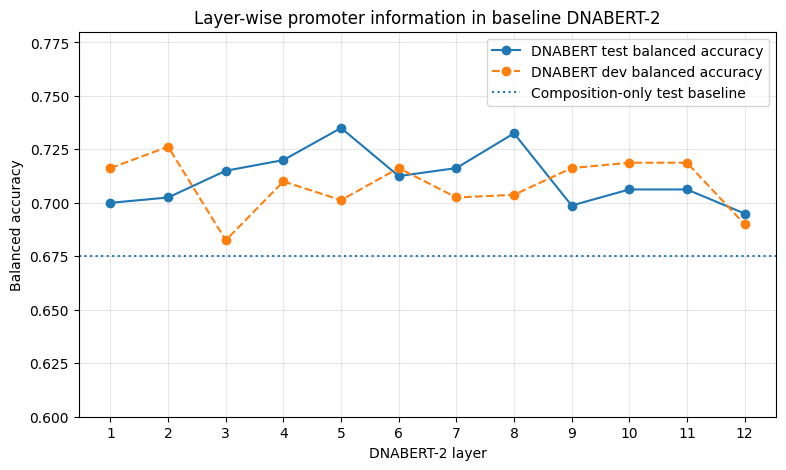

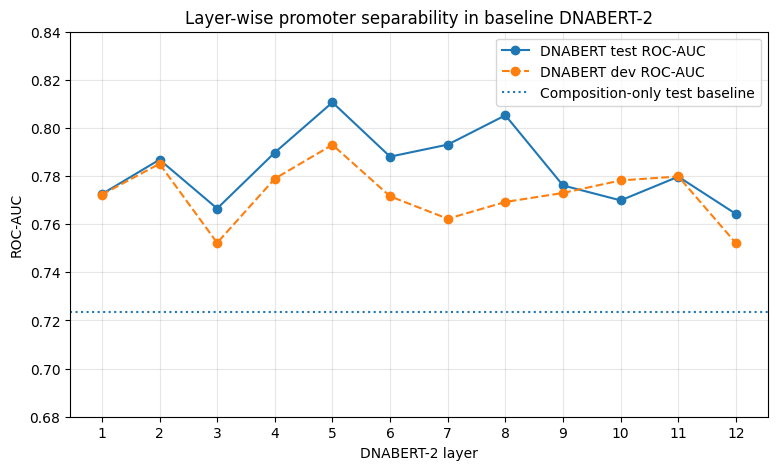

In [16]:
# Plot layer-wise promoter probe performance

import matplotlib.pyplot as plt

test_probe_results = (
    layer_probe_results[
        layer_probe_results["split"] == "test"
    ]
    .sort_values("layer")
    .reset_index(drop=True)
)

dev_probe_results = (
    layer_probe_results[
        layer_probe_results["split"] == "dev"
    ]
    .sort_values("layer")
    .reset_index(drop=True)
)

COMPOSITION_TEST_ACCURACY = 0.675
COMPOSITION_TEST_AUC = 0.723532

plt.figure(figsize=(9, 5))

plt.plot(
    test_probe_results["layer"],
    test_probe_results["balanced_accuracy"],
    marker="o",
    label="DNABERT test balanced accuracy",
)

plt.plot(
    dev_probe_results["layer"],
    dev_probe_results["balanced_accuracy"],
    marker="o",
    linestyle="--",
    label="DNABERT dev balanced accuracy",
)

plt.axhline(
    COMPOSITION_TEST_ACCURACY,
    linestyle=":",
    label="Composition-only test baseline",
)

plt.xlabel("DNABERT-2 layer")
plt.ylabel("Balanced accuracy")
plt.title("Layer-wise promoter information in baseline DNABERT-2")
plt.xticks(range(1, 13))
plt.ylim(0.60, 0.78)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


plt.figure(figsize=(9, 5))

plt.plot(
    test_probe_results["layer"],
    test_probe_results["roc_auc"],
    marker="o",
    label="DNABERT test ROC-AUC",
)

plt.plot(
    dev_probe_results["layer"],
    dev_probe_results["roc_auc"],
    marker="o",
    linestyle="--",
    label="DNABERT dev ROC-AUC",
)

plt.axhline(
    COMPOSITION_TEST_AUC,
    linestyle=":",
    label="Composition-only test baseline",
)

plt.xlabel("DNABERT-2 layer")
plt.ylabel("ROC-AUC")
plt.title("Layer-wise promoter separability in baseline DNABERT-2")
plt.xticks(range(1, 13))
plt.ylim(0.68, 0.84)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

k-mer frequency baseline

In [17]:
# Train classifiers using 1-mer, 2-mer, and 3-mer frequencies only

from itertools import product
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
)

DNA_ALPHABET = "ACGT"


def all_kmers(k):
    return [
        "".join(chars)
        for chars in product(DNA_ALPHABET, repeat=k)
    ]


def kmer_frequency_features(sequence, k):
    """
    Return normalized frequencies for every possible DNA k-mer.
    """
    sequence = sequence.upper()
    kmers = all_kmers(k)

    counts = {kmer: 0 for kmer in kmers}

    total_windows = len(sequence) - k + 1

    for start in range(total_windows):
        kmer = sequence[start:start + k]

        if kmer in counts:
            counts[kmer] += 1

    if total_windows > 0:
        counts = {
            kmer: count / total_windows
            for kmer, count in counts.items()
        }

    return counts


def build_kmer_matrix(dataset_split, k):
    sequences = dataset_split["sequence"]

    feature_rows = [
        kmer_frequency_features(sequence, k)
        for sequence in sequences
    ]

    feature_df = pd.DataFrame(feature_rows)

    return feature_df.to_numpy(), np.array(dataset_split["label"])


kmer_baseline_rows = []
kmer_models = {}

for k in [1, 2, 3]:
    print(f"Building {k}-mer features...")

    X_train_kmer, y_train_kmer = build_kmer_matrix(
        pilot_train,
        k,
    )

    X_dev_kmer, y_dev_kmer = build_kmer_matrix(
        pilot_dev,
        k,
    )

    X_test_kmer, y_test_kmer = build_kmer_matrix(
        pilot_test,
        k,
    )

    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=SEED,
            solver="liblinear",
        ),
    )

    classifier.fit(X_train_kmer, y_train_kmer)
    kmer_models[k] = classifier

    for split_name, X_split, y_split in [
        ("dev", X_dev_kmer, y_dev_kmer),
        ("test", X_test_kmer, y_test_kmer),
    ]:
        predictions = classifier.predict(X_split)
        probabilities = classifier.predict_proba(X_split)[:, 1]

        kmer_baseline_rows.append({
            "k": k,
            "num_features": X_train_kmer.shape[1],
            "split": split_name,
            "accuracy": accuracy_score(
                y_split,
                predictions,
            ),
            "balanced_accuracy": balanced_accuracy_score(
                y_split,
                predictions,
            ),
            "roc_auc": roc_auc_score(
                y_split,
                probabilities,
            ),
        })

kmer_baseline_results = pd.DataFrame(kmer_baseline_rows)

display(kmer_baseline_results)

Building 1-mer features...
Building 2-mer features...
Building 3-mer features...


,k,num_features,split,accuracy,balanced_accuracy,roc_auc
0,1,4,dev,0.66000,0.66000,0.707053
1,1,4,test,0.67250,0.67250,0.720494
2,2,16,dev,0.74250,0.74250,0.817937
3,2,16,test,0.76000,0.76000,0.830469
4,3,64,dev,0.76625,0.76625,0.830819
5,3,64,test,0.76375,0.76375,0.845600


consolidated comparison

,model,balanced_accuracy,roc_auc
2,3-mer logistic regression,0.76375,0.845600
1,2-mer logistic regression,0.76000,0.830469
3,DNABERT-2 layer 5,0.73500,0.810638
0,1-mer logistic regression,0.67250,0.720494


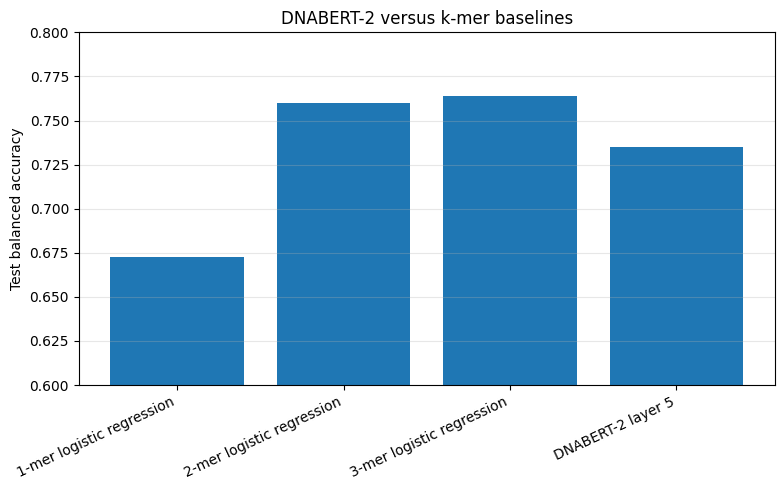

In [18]:
best_dnabert_test = (
    layer_probe_results[
        layer_probe_results["split"] == "test"
    ]
    .sort_values("balanced_accuracy", ascending=False)
    .iloc[0]
)

baseline_comparison = pd.DataFrame([
    {
        "model": "1-mer logistic regression",
        "balanced_accuracy": kmer_baseline_results.query(
            "k == 1 and split == 'test'"
        )["balanced_accuracy"].iloc[0],
        "roc_auc": kmer_baseline_results.query(
            "k == 1 and split == 'test'"
        )["roc_auc"].iloc[0],
    },
    {
        "model": "2-mer logistic regression",
        "balanced_accuracy": kmer_baseline_results.query(
            "k == 2 and split == 'test'"
        )["balanced_accuracy"].iloc[0],
        "roc_auc": kmer_baseline_results.query(
            "k == 2 and split == 'test'"
        )["roc_auc"].iloc[0],
    },
    {
        "model": "3-mer logistic regression",
        "balanced_accuracy": kmer_baseline_results.query(
            "k == 3 and split == 'test'"
        )["balanced_accuracy"].iloc[0],
        "roc_auc": kmer_baseline_results.query(
            "k == 3 and split == 'test'"
        )["roc_auc"].iloc[0],
    },
    {
        "model": f"DNABERT-2 layer {int(best_dnabert_test['layer'])}",
        "balanced_accuracy": best_dnabert_test["balanced_accuracy"],
        "roc_auc": best_dnabert_test["roc_auc"],
    },
])

display(
    baseline_comparison.sort_values(
        "balanced_accuracy",
        ascending=False,
    )
)

plt.figure(figsize=(8, 5))

plt.bar(
    baseline_comparison["model"],
    baseline_comparison["balanced_accuracy"],
)

plt.ylabel("Test balanced accuracy")
plt.title("DNABERT-2 versus k-mer baselines")
plt.ylim(0.60, 0.80)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

shuffled-label control

In [19]:
from sklearn.utils import shuffle

BEST_LAYER_INDEX = 4  # Layer 5 in zero-based indexing
NUM_LABEL_SHUFFLES = 20

X_train_best = pilot_train_representations[BEST_LAYER_INDEX]
X_test_best = pilot_test_representations[BEST_LAYER_INDEX]

shuffled_control_rows = []

for shuffle_index in range(NUM_LABEL_SHUFFLES):
    shuffled_train_labels = shuffle(
        pilot_train_labels,
        random_state=SEED + shuffle_index,
    )

    shuffled_probe = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            random_state=SEED,
            solver="liblinear",
        ),
    )

    shuffled_probe.fit(
        X_train_best,
        shuffled_train_labels,
    )

    predictions = shuffled_probe.predict(X_test_best)
    probabilities = shuffled_probe.predict_proba(
        X_test_best
    )[:, 1]

    shuffled_control_rows.append({
        "shuffle": shuffle_index,
        "balanced_accuracy": balanced_accuracy_score(
            pilot_test_labels,
            predictions,
        ),
        "roc_auc": roc_auc_score(
            pilot_test_labels,
            probabilities,
        ),
    })

shuffled_label_results = pd.DataFrame(
    shuffled_control_rows
)

display(shuffled_label_results.describe())

print(
    "\nObserved Layer 5 balanced accuracy:",
    best_dnabert_test["balanced_accuracy"],
)

print(
    "Mean shuffled-label balanced accuracy:",
    shuffled_label_results["balanced_accuracy"].mean(),
)

print(
    "Observed Layer 5 ROC-AUC:",
    best_dnabert_test["roc_auc"],
)

print(
    "Mean shuffled-label ROC-AUC:",
    shuffled_label_results["roc_auc"].mean(),
)

,shuffle,balanced_accuracy,roc_auc
count,20.00000,20.000000,20.000000
mean,9.50000,0.500312,0.499635
std,5.91608,0.015591,0.020085
min,0.00000,0.473750,0.466419
25%,4.75000,0.490625,0.482236
50%,9.50000,0.496875,0.502428
75%,14.25000,0.510000,0.508556
max,19.00000,0.540000,0.551087



Observed Layer 5 balanced accuracy: 0.7350000000000001
Mean shuffled-label balanced accuracy: 0.5003124999999999
Observed Layer 5 ROC-AUC: 0.8106375000000001
Mean shuffled-label ROC-AUC: 0.4996353125


save results

In [20]:
# Save tables and pilot representations

from pathlib import Path
import joblib

# OUTPUT_DIR is defined in the Drive-mount cell at the top of this notebook.
OUTPUT_DIR = Path("/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

dataset_summary.to_csv(
    OUTPUT_DIR / "dataset_summary.csv",
    index=False,
)

composition_results.to_csv(
    OUTPUT_DIR / "composition_baseline.csv",
    index=False,
)

layer_probe_results.to_csv(
    OUTPUT_DIR / "layer_probe_results.csv",
    index=False,
)

kmer_baseline_results.to_csv(
    OUTPUT_DIR / "kmer_baseline_results.csv",
    index=False,
)

baseline_comparison.to_csv(
    OUTPUT_DIR / "baseline_comparison.csv",
    index=False,
)

shuffled_label_results.to_csv(
    OUTPUT_DIR / "shuffled_label_control.csv",
    index=False,
)

# Save the best Layer 5 probe.
joblib.dump(
    probe_models[BEST_LAYER_INDEX],
    OUTPUT_DIR / "dnabert_layer5_probe.joblib",
)

# Save compact NumPy arrays for the best layer.
np.save(
    OUTPUT_DIR / "layer5_train_representations.npy",
    pilot_train_representations[BEST_LAYER_INDEX],
)

np.save(
    OUTPUT_DIR / "layer5_dev_representations.npy",
    pilot_dev_representations[BEST_LAYER_INDEX],
)

np.save(
    OUTPUT_DIR / "layer5_test_representations.npy",
    pilot_test_representations[BEST_LAYER_INDEX],
)

np.save(
    OUTPUT_DIR / "train_labels.npy",
    pilot_train_labels,
)

np.save(
    OUTPUT_DIR / "dev_labels.npy",
    pilot_dev_labels,
)

np.save(
    OUTPUT_DIR / "test_labels.npy",
    pilot_test_labels,
)

print("Saved files:")

for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path)

Saved files:
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/baseline_comparison.csv
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/composition_baseline.csv
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/dataset_summary.csv
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/dev_labels.npy
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/dnabert_layer5_probe.joblib
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/kmer_baseline_results.csv
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/layer5_dev_representations.npy
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/layer5_test_representations.npy
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/layer5_train_representations.npy
- /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/lay

cleanup cell

In [21]:
for handle in hook_handles:
    handle.remove()

hook_handles.clear()
captured_layers.clear()

print("All hooks removed.")

All hooks removed.


# Pilot conclusion

Using the GUE `prom_core_all` dataset, baseline non-fine-tuned DNABERT-2 representations contained promoter-label information across all 12 layers.

The strongest mean-pooled representation occurred at Layer 5:

- Test balanced accuracy: 0.735
- Test ROC-AUC: 0.811

The shuffled-label control returned chance-level performance:

- Mean balanced accuracy: 0.500
- Mean ROC-AUC: 0.500

However, simple local sequence-statistics baselines performed better:

- 1-mer: 0.673 balanced accuracy
- 2-mer: 0.760 balanced accuracy
- 3-mer: 0.764 balanced accuracy

Therefore, this pilot establishes that promoter information is decodable from baseline DNABERT-2, but it does not yet show that the model represents promoter biology beyond short k-mer statistics.

The next experiment should use controlled promoter corruptions and matched controls to distinguish:

1. nucleotide composition,
2. local k-mer statistics,
3. motif identity,
4. motif position,
5. surrounding promoter context.